# 01. 데이터 이해 (EDA)

**목적**: 무엇이 D+3 상승과 관련 있는지 확인하고, 덩어리 3(피처 만들기)의 근거와 보고서용 그림을 만든다.

**원칙**
- 타깃과 관련된 통계는 **train으로만** 계산한다. test는 5절의 맥락 설명용 그림 하나에만 쓰고, 어떤 판단에도 쓰지 않는다.
- 이 노트북의 순위와 판단은 **아이디어를 얻기 위한 것**이다. 실제 피처 선택은 덩어리 3·4에서 CV fold 안에서 다시 한다. 전체 train으로 고른 피처를 같은 train으로 검증하면 점수가 부풀려지기 때문이다.
- 그림은 `outputs/figures/`에 저장된다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import plotting as P
from src.data import TARGETS, feature_columns, load_data
from src.eda import auc_scorer, shift_null_max, stratified_auc_scorer

P.setup()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

train, test = load_data()
features = feature_columns(train)
WEEKDAY_NAMES = {1: "일", 2: "월", 3: "화", 4: "수", 5: "목", 6: "금", 7: "토"}
TARGET_NAMES = {"Target_1": "Target_1 (KOSPI)", "Target_2": "Target_2 (건강식품)"}

## 1. 기본 점검

In [2]:
values = pd.concat([train, test])[[c for c in features if c != "Weekday"]]
category = pd.Series([c.split("_")[0] for c in features if c != "Weekday"])
constant = [c for c in features if train[c].nunique() <= 1]

pd.DataFrame(
    {
        "값": [
            f"{len(train)}행 (Time_step {train.Time_step.min()}~{train.Time_step.max()})",
            f"{len(test)}행 (Time_step {test.Time_step.min()}~{test.Time_step.max()}), 앞 100행이 Public",
            f"{len(features)}개 = Weekday 1 + " + ", ".join(f"{k} {v}" for k, v in category.value_counts().items()),
            f"{int(train[features].isna().sum().sum())}개",
            f"{values.min().min():.3f} ~ {values.max().max():.3f}",
            ", ".join(constant),
            ", ".join(f"{t} {train[t].mean():.3f}" for t in TARGETS),
        ]
    },
    index=["학습 데이터", "평가 데이터", "설명변수", "train 결측", "설명변수 값 범위 (train+test)", "train 상수 컬럼", "상승(1) 비율"],
)

,값
학습 데이터,924행 (Time_step 1~924)
평가 데이터,"200행 (Time_step 925~1124), 앞 100행이 Public"
설명변수,"284개 = Weekday 1 + SH2 188, KE 51, FI 18, WE 15, SH1 11"
train 결측,0개
설명변수 값 범위 (train+test),0.000 ~ 1.000
train 상수 컬럼,KE_QR체크인
상승(1) 비율,"Target_1 0.516, Target_2 0.470"


In [3]:
# Weekday 번호가 어느 요일인지: 주식·환율 시장이 쉬는 날은 전날 대비 변화가 0
market = ["FI_Dow", "FI_Nasdaq", "FI_FX_USDKRW"]
(train[market].diff().abs() < 1e-12).groupby(train["Weekday"]).mean().round(2).T

Weekday,1,2,3,4,5,6,7
FI_Dow,1.0,0.09,0.02,0.03,0.03,0.02,1.0
FI_Nasdaq,1.0,0.09,0.02,0.03,0.03,0.02,1.0
FI_FX_USDKRW,1.0,0.12,0.14,0.16,0.08,0.08,1.0


- 설명변수는 결측이 없고 **0~1 범위**다. 변수 설명서에는 "표준화"라고 되어 있지만 실제로는 0~1 정규화다. 따라서 추가 스케일링은 선형모델에만 필요하고, 트리 모델에는 필요 없다.
- `KE_QR체크인`은 train 전체가 0인 상수라서 제거 대상이다.
- Weekday 1과 7에서 시장 변수의 변화가 100% 0이다. 따라서 **1 = 일요일, 7 = 토요일**이고, 주말에는 금요일 값이 그대로 이어진다.

## 2. 타깃 이해

In [4]:
thirds = np.repeat(["1/3", "2/3", "3/3"], len(train) // 3)
train.groupby(thirds)[TARGETS].mean().round(3).rename_axis("train 구간")

,Target_1,Target_2
train 구간,,
1/3,0.526,0.468
2/3,0.500,0.461
3/3,0.523,0.481


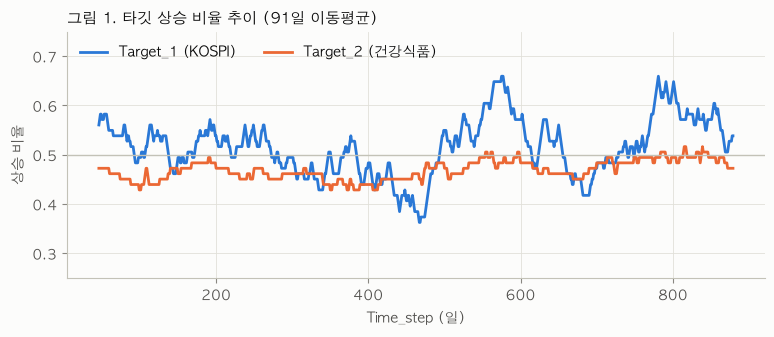

In [5]:
window = 91  # 13주: 각 창에 요일이 같은 수만큼 들어감
rolling = train[TARGETS].rolling(window, center=True).mean()

fig, ax = plt.subplots(figsize=(9, 3.2))
for t in TARGETS:
    ax.plot(train["Time_step"], rolling[t], color=P.COLORS[t], label=TARGET_NAMES[t])
ax.axhline(0.5, color=P.AXIS, lw=1)
ax.set(ylim=(0.25, 0.75), xlabel="Time_step (일)", ylabel="상승 비율", title="")
ax.set_title(f"그림 1. 타깃 상승 비율 추이 ({window}일 이동평균)", loc="left")
ax.legend(loc="upper left", ncols=2)
P.save(fig, "fig1_target_trend")

,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Target_1,0.47,0.25,0.05,0.02,-0.00,-0.02,0.01,-0.02,-0.01,-0.06,-0.05,-0.06,-0.05,-0.10
Target_2,0.42,-0.13,-0.63,-0.64,-0.14,0.36,0.70,0.36,-0.14,-0.61,-0.58,-0.14,0.36,0.72


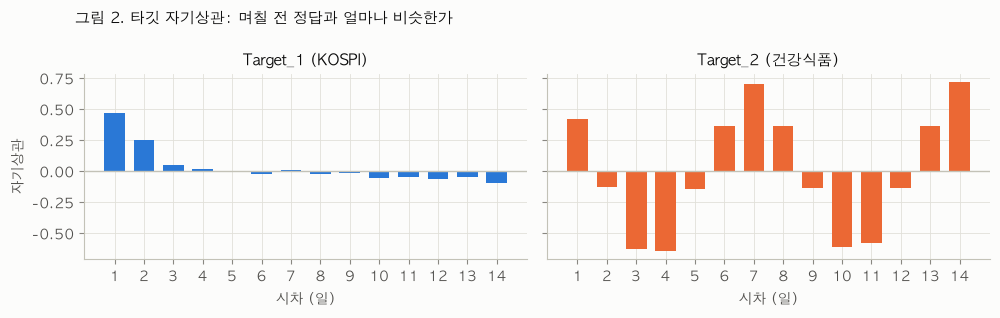

In [6]:
lags = np.arange(1, 15)
acf = pd.DataFrame({t: [train[t].autocorr(lag) for lag in lags] for t in TARGETS}, index=lags)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, t in zip(axes, TARGETS):
    ax.bar(lags, acf[t], color=P.COLORS[t], width=0.7)
    ax.axhline(0, color=P.AXIS, lw=1)
    ax.set(title=TARGET_NAMES[t], xlabel="시차 (일)", xticks=lags)
axes[0].set_ylabel("자기상관")
fig.suptitle("그림 2. 타깃 자기상관: 며칠 전 정답과 얼마나 비슷한가", x=0.07, ha="left", fontsize=11)
fig.tight_layout()
P.save(fig, "fig2_target_autocorr")
acf.round(2).T

- 두 타깃 모두 상승 비율이 0.5 근처로 **균형적**이다. train을 3등분한 구간 평균도 0.46~0.53으로 안정적이다.
- 다만 **Target_1은 3개월 단위로 0.37~0.66까지 출렁인다** (시장 상승기·하락기). 100일짜리 검증 구간마다 점수가 크게 흔들리는 이유 중 하나다.
- **Target_1**: 자기상관이 1일 0.47, 2일 0.25이고 3일부터는 거의 0이다. D+3 라벨은 기간이 3일이라 이웃한 날끼리 겹친다. 그래서 검증에서 학습과 검증 사이를 **3일 비우는 설계**(덩어리 1)가 필요하다.
- **Target_2**: 7일, 14일에서 0.7이 넘는 **주간 주기**가 있다. 요일이 결정적이라는 뜻이다 (3절).
- 테스트에는 정답이 없으므로, 과거 정답을 입력으로 쓰는 방식은 불가능하다.

## 3. 요일 효과

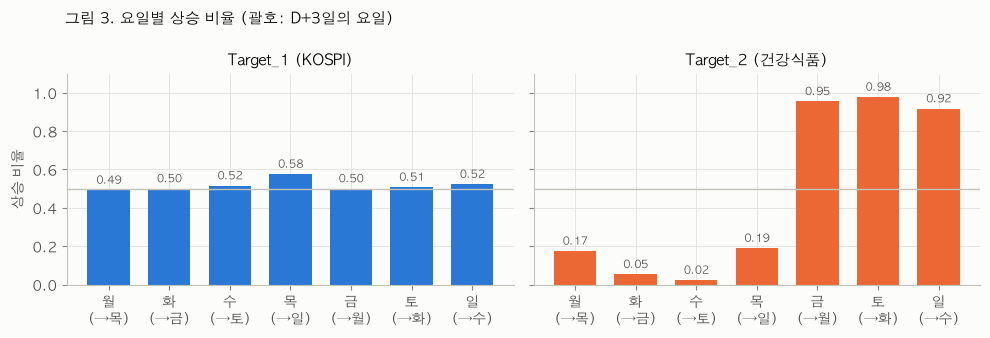

In [7]:
order = [2, 3, 4, 5, 6, 7, 1]  # 월~일
labels = [f"{WEEKDAY_NAMES[w]}\n(→{WEEKDAY_NAMES[(w + 2) % 7 + 1]})" for w in order]  # D+3의 요일
rate = train.groupby("Weekday")[TARGETS].mean().loc[order]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, t in zip(axes, TARGETS):
    bars = ax.bar(range(7), rate[t], color=P.COLORS[t], width=0.7)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in rate[t]], padding=2, fontsize=8, color=P.INK_SECONDARY)
    ax.axhline(0.5, color=P.AXIS, lw=1)
    ax.set(title=TARGET_NAMES[t], xticks=range(7), xticklabels=labels, ylim=(0, 1.1))
axes[0].set_ylabel("상승 비율")
fig.suptitle("그림 3. 요일별 상승 비율 (괄호: D+3일의 요일)", x=0.07, ha="left", fontsize=11)
fig.tight_layout()
P.save(fig, "fig3_weekday")

In [8]:
# 요일 효과가 기간에 따라 안정적인가
pd.concat(
    {t: train.pivot_table(index=thirds, columns="Weekday", values=t).rename(columns=WEEKDAY_NAMES)[[WEEKDAY_NAMES[w] for w in order]] for t in TARGETS}
).round(2)

Weekday          월     화     수     목     금     토     일
Target_1 1/3  0.48  0.52  0.59  0.55  0.52  0.50  0.52
         2/3  0.50  0.50  0.45  0.64  0.45  0.41  0.55
         3/3  0.50  0.48  0.50  0.55  0.52  0.61  0.50
Target_2 1/3  0.20  0.05  0.02  0.14  0.95  0.98  0.93
         2/3  0.16  0.07  0.00  0.18  0.91  1.00  0.91
         3/3  0.16  0.05  0.05  0.25  1.00  0.95  0.91

- **Target_2는 요일로 거의 결정된다.** 금·토·일(D+3이 월·화·수)은 90% 이상 상승하고, 화·수(D+3이 금·토)는 5% 이하다. 건강식품 클릭은 평일 초반에 높고 주말에 낮다고 해석할 수 있다.
- 이 패턴은 train의 세 구간에서 모두 거의 같다. **테스트 기간에도 유지될 가능성이 높다.**
- 남은 불확실성은 **월(0.17)과 목(0.19)**에 몰려 있다. Target_2의 개선 여지는 "같은 요일 안에서 어느 날이 오를지"를 구분하는 데 있다.
- **Target_1은 요일 효과가 없다.** 구간마다 들쭉날쭉한 차이는 표본 수(칸당 약 44일)로 인한 잡음 수준이다.

## 4. 변수와 정답의 관계

변수 하나를 점수로 썼을 때의 AUC를 모든 변수에 대해 계산한다.
- **후보**: 원래값과 1·3·7일 변화량 (282개 × 4 = 1,128개). 변화량 계산에 필요한 앞 7일은 제외한다.
- **우연 기준선**: 후보가 1,000개가 넘으면 관계가 없어도 우연히 높은 AUC가 나온다. 타깃을 시간축으로 순환 이동시켜 실제 관계만 끊고 자기상관은 유지한 채 200번 계산한다. 그때 나오는 최대 |AUC−0.5|의 95분위를 기준선으로 삼는다. 이 선을 넘어야 우연이 아닐 가능성이 높다.
- **Target_2**는 요일 효과를 빼야 의미가 있으므로 **같은 요일끼리만 비교하는 AUC**를 쓴다. 이때 순환 이동은 7일 배수로만 한다.
- **전후반 일관성**: train 전반부와 후반부에서 관계의 방향이 같은지도 확인한다.

In [9]:
base = [c for c in features if c != "Weekday" and c not in constant]
blocks = {"원래값": train[base]} | {f"{k}일 변화": train[base].diff(k) for k in (1, 3, 7)}
candidates = pd.concat(blocks, axis=1).iloc[7:]
X = candidates.to_numpy()
y = train[TARGETS].iloc[7:].to_numpy()
weekday = train["Weekday"].iloc[7:].to_numpy()
half = len(X) // 2


def univariate(make_scorer, yt, step):
    idx = np.arange(len(yt))
    table = pd.DataFrame(
        {
            "AUC": make_scorer(idx)(yt),
            "AUC_전반": make_scorer(idx[:half])(yt[:half]),
            "AUC_후반": make_scorer(idx[half:])(yt[half:]),
        },
        index=candidates.columns.set_names(["형태", "변수"]),
    )
    table["강도"] = (table["AUC"] - 0.5).abs()
    table["방향"] = np.where(table["AUC"] >= 0.5, "+", "-")
    table["전후반_일관"] = np.sign(table["AUC_전반"] - 0.5) == np.sign(table["AUC_후반"] - 0.5)
    null95 = np.percentile(shift_null_max(make_scorer(idx), yt, step=step), 95)
    return table.sort_values("강도", ascending=False), null95


uni = {
    "Target_1": univariate(lambda m: auc_scorer(X[m]), y[:, 0], step=1),
    "Target_2": univariate(lambda m: stratified_auc_scorer(X[m], weekday[m]), y[:, 1], step=7),
}
for t, (table, null95) in uni.items():
    passed = table[table["강도"] > null95]
    print(f"{t}: 우연 기준선 |AUC-0.5| = {null95:.3f} (AUC {0.5 + null95:.3f}), 넘은 후보 {len(passed)}개, 그중 전후반 일관 {passed['전후반_일관'].sum()}개")

Target_1: 우연 기준선 |AUC-0.5| = 0.097 (AUC 0.597), 넘은 후보 3개, 그중 전후반 일관 3개
Target_2: 우연 기준선 |AUC-0.5| = 0.158 (AUC 0.658), 넘은 후보 63개, 그중 전후반 일관 63개


In [10]:
uni["Target_1"][0].head(10).round(3)

AUC  AUC_전반  AUC_후반     강도 방향  전후반_일관
형태    변수                                                          
1일 변화 FI_Sp500             0.601   0.599   0.602  0.101  +    True
3일 변화 FI_Sp500             0.600   0.603   0.597  0.100  +    True
1일 변화 FI_Dow               0.597   0.602   0.594  0.097  +    True
3일 변화 FI_Dow               0.592   0.597   0.591  0.092  +    True
      FI_Nasdaq            0.589   0.581   0.594  0.089  +    True
1일 변화 FI_Nasdaq            0.584   0.576   0.591  0.084  +    True
7일 변화 SH2_쇼핑2_가구인테리어_수예    0.575   0.555   0.597  0.075  +    True
원래값   SH2_쇼핑2_생활건강_악기      0.575   0.560   0.591  0.075  +    True
      SH2_쇼핑2_출산육아_구강청결용품  0.573   0.563   0.579  0.073  +    True
      SH2_쇼핑2_출산육아_수유용품    0.572   0.560   0.572  0.072  +    True

In [11]:
uni["Target_2"][0].head(10).round(3)

AUC  AUC_전반  AUC_후반     강도 방향  전후반_일관
형태    변수                                                         
1일 변화 SH1_쇼핑1_가구인테리어      0.714   0.738   0.700  0.214  +    True
3일 변화 KE_비대면              0.709   0.726   0.701  0.209  +    True
원래값   KE_보험               0.291   0.333   0.270  0.209  -    True
3일 변화 KE_재택근무             0.294   0.315   0.280  0.206  -    True
1일 변화 SH1_쇼핑1_디지털가전       0.704   0.690   0.708  0.204  +    True
      SH1_쇼핑1_화자품미용       0.698   0.695   0.717  0.198  +    True
      KE_사회적기업            0.303   0.295   0.313  0.197  -    True
3일 변화 SH2_쇼핑2_스포츠레저_배드민턴  0.304   0.355   0.260  0.196  -    True
      KE_종신_여성_20대이하      0.311   0.337   0.291  0.189  -    True
      KE_화상회의             0.311   0.310   0.316  0.189  -    True

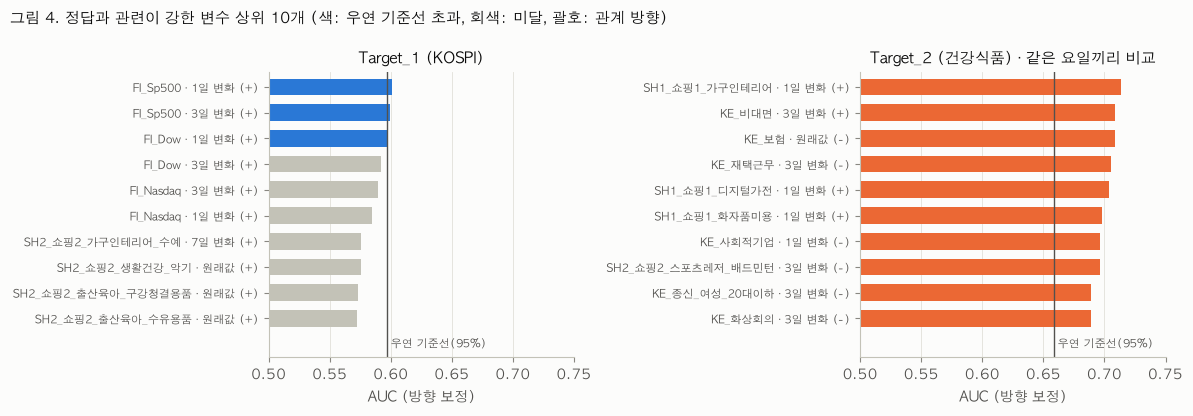

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, t in zip(axes, TARGETS):
    table, null95 = uni[t]
    top = table.head(10).iloc[::-1]
    strength = 0.5 + top["강도"]
    colors = [P.COLORS[t] if s > null95 else P.AXIS for s in top["강도"]]
    ax.barh(range(len(top)), strength, color=colors, height=0.65)
    ax.axvline(0.5 + null95, color=P.INK_SECONDARY, lw=1)
    ax.text(0.5 + null95, -1.0, " 우연 기준선(95%)", fontsize=8, color=P.INK_SECONDARY, va="center")
    ax.set_yticks(range(len(top)), [f"{v} · {k} ({d})" for (k, v), d in zip(top.index, top["방향"])], fontsize=8)
    ax.set(xlim=(0.5, 0.75), ylim=(-1.5, len(top) - 0.4), xlabel="AUC (방향 보정)", title=TARGET_NAMES[t] + (" · 같은 요일끼리 비교" if t == "Target_2" else ""))
    ax.grid(axis="y", visible=False)
fig.suptitle("그림 4. 정답과 관련이 강한 변수 상위 10개 (색: 우연 기준선 초과, 회색: 미달, 괄호: 관계 방향)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
P.save(fig, "fig4_univariate_top")

In [13]:
# 원래값 vs 변화량: 카테고리별 평균 강도
pd.concat({t: uni[t][0]["강도"].groupby([uni[t][0].index.get_level_values("형태"), uni[t][0].index.get_level_values("변수").str.split("_").str[0]]).mean().unstack() for t in TARGETS}).round(3)

변수                 FI     KE    SH1    SH2     WE
         형태                                      
Target_1 1일 변화  0.035  0.016  0.016  0.009  0.009
         3일 변화  0.037  0.012  0.014  0.009  0.016
         7일 변화  0.030  0.027  0.019  0.022  0.024
         원래값    0.024  0.031  0.024  0.032  0.027
Target_2 1일 변화  0.019  0.083  0.086  0.054  0.030
         3일 변화  0.032  0.120  0.078  0.100  0.034
         7일 변화  0.024  0.098  0.081  0.081  0.025
         원래값    0.034  0.110  0.057  0.060  0.022

**Target_1 (KOSPI)**
- 우연 기준선을 넘는 후보는 **3개(S&P500 1·3일 변화, Dow 1일 변화)**이고, **상위 6개가 모두 미국 지수(S&P500, Dow, Nasdaq)의 1·3일 변화량**이다. 이 관계는 전반과 후반 모두에서 AUC 약 0.58~0.60으로 일관된다. 방향은 +로, 미국 증시가 오르면 며칠 뒤 KOSPI도 오르는 경향이다. 경제적으로도 설명된다.
- 그다음 순위의 쇼핑 변수(원래값, 7일 변화)는 AUC 0.57 수준으로 기준선 아래다. 5절에서 보듯 원래값은 시기에 따라 크게 움직여 우연한 상관이 생기기 쉽다.
- 카테고리별로 보면 금융(FI)은 원래값보다 **변화량에서 더 강하다.**

**Target_2 (건강식품, 요일 효과 제거 후)**
- 같은 요일 안에서도 기준선(AUC 0.658)을 넘는 후보가 **63개**이고, 모두 전후반 방향이 일관된다. 상위는 쇼핑 Level 1 카테고리의 1일 변화량, 검색어의 3일 변화량 등이다.
- 특정 상품보다는 **포털·쇼핑 전체 트래픽의 흐름**으로 보인다 (가설). 예를 들어 연휴처럼 전체 이용량이 출렁이는 시기의 영향일 수 있다.
- 비슷한 신호가 여러 변수에 흩어져 있다. 그래서 개별 변수보다 **카테고리 평균 같은 집계 지표**로 묶으면 잡음이 줄어들 것으로 기대한다.

## 5. 시기별 변화 (드리프트)

train의 **마지막 200일**(Private 평가 길이)이 그 이전과 얼마나 다른지 본다. train 안에서만 비교한다.
- **SMD**: 평균 차이를 이전 기간의 표준편차로 나눈 값. 1을 넘으면 크게 이동한 것이다.
- **범위 밖 비율**: 마지막 200일 값 중 이전 기간의 최소~최대를 벗어난 비율. 트리 모델은 학습 범위 밖의 값을 외삽하지 못한다.

In [14]:
drift = {}
for name, frame in blocks.items():
    frame = frame.iloc[7:]
    before, recent = frame.iloc[:-200], frame.iloc[-200:]
    smd = ((recent.mean() - before.mean()) / before.std()).abs()
    outside = ((recent < before.min()) | (recent > before.max())).mean()
    drift[name] = {"SMD 중앙값": smd.median(), "SMD>1 변수 수": (smd > 1).sum(), "범위 밖 10% 초과 변수 수": (outside > 0.1).sum()}
    if name == "원래값":
        level_drift = pd.DataFrame({"SMD": smd, "범위 밖 비율": outside})
pd.DataFrame(drift).T.round(2)

,SMD 중앙값,SMD>1 변수 수,범위 밖 10% 초과 변수 수
원래값,0.65,115.0,43.0
1일 변화,0.01,1.0,3.0
3일 변화,0.02,1.0,5.0
7일 변화,0.06,2.0,8.0


In [15]:
level_drift.loc[["FI_Sp500", "FI_Dow", "FI_Nasdaq"]].round(2)

,SMD,범위 밖 비율
FI_Sp500,2.50,0.56
FI_Dow,2.01,0.50
FI_Nasdaq,2.21,0.53


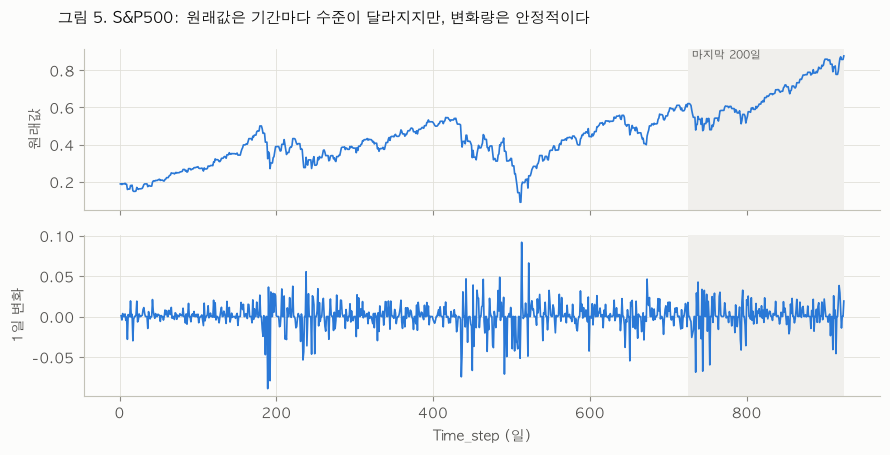

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
series = {"원래값": train["FI_Sp500"], "1일 변화": train["FI_Sp500"].diff()}
for ax, (name, s) in zip(axes, series.items()):
    ax.axvspan(train.Time_step.iloc[-200], train.Time_step.iloc[-1], color=P.SHADE, lw=0)
    ax.plot(train["Time_step"], s, color=P.SERIES[0], lw=1.2)
    ax.set_ylabel(name)
axes[0].text(train.Time_step.iloc[-200], axes[0].get_ylim()[1], " 마지막 200일", fontsize=8, color=P.INK_SECONDARY, va="top")
axes[1].set_xlabel("Time_step (일)")
fig.suptitle("그림 5. S&P500: 원래값은 기간마다 수준이 달라지지만, 변화량은 안정적이다", x=0.07, ha="left", fontsize=11)
fig.tight_layout()
P.save(fig, "fig5_level_vs_change")

**참고 (판단에 사용하지 않음)**: 테스트 기간의 입력값 추이. 테스트 기간이 학습 기간과 얼마나 다른 환경인지 보여주는 맥락 설명용이다.

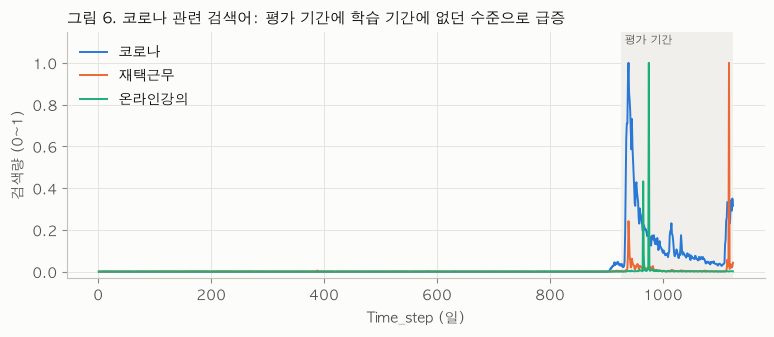

In [17]:
full = pd.concat([train, test], ignore_index=True)
keywords = ["KE_코로나", "KE_재택근무", "KE_온라인강의"]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axvspan(test.Time_step.iloc[0], test.Time_step.iloc[-1], color=P.SHADE, lw=0)
for kw, color in zip(keywords, P.SERIES):
    ax.plot(full["Time_step"], full[kw], color=color, lw=1.4, label=kw.removeprefix("KE_"))
ax.text(test.Time_step.iloc[0], 1.14, " 평가 기간", fontsize=8, color=P.INK_SECONDARY, va="top")
ax.set(xlabel="Time_step (일)", ylabel="검색량 (0~1)", ylim=(-0.03, 1.15))
ax.set_title("그림 6. 코로나 관련 검색어: 평가 기간에 학습 기간에 없던 수준으로 급증", loc="left")
ax.legend(loc="upper left")
P.save(fig, "fig6_covid_keywords")

- **원래값은 train 안에서도 크게 이동한다.** 282개 중 115개가 SMD 1을 넘는다. 미국 지수는 마지막 200일 값의 절반 이상이 이전 범위 밖에 있다. 트리 모델에 원래값을 넣으면 처음 보는 수준에서 판단이 무너진다.
- **변화량은 안정적이다.** SMD 중앙값이 0.01~0.06이다. 4절에서 Target_1 신호가 변화량에서 나온 것과 같은 방향이다.
- 평가 기간에는 코로나 관련 검색어가 학습 기간에 없던 수준으로 치솟는다(그림 6). 이런 변수의 원래값에 의존하는 모델은 평가 기간에 위험하다.

## 6. 정리: 발견 → 덩어리 3에서 할 일

| # | 발견 | 근거 | 덩어리 3에서 할 일 |
|---|---|---|---|
| 1 | Target_1의 신호는 **미국 지수 변화량**에서만 우연 기준선을 넘는다 | 4절, 그림 4 | 미국 지수의 1·3일 변화를 중심으로, 지수 평균 변화, 누적 변화, 최근 변동성 같은 파생을 만든다 |
| 2 | **원래값은 드리프트가 심하고 변화량은 안정적이다** | 5절, 그림 5 | 변화량 기반 피처를 기본으로 하고, 원래값은 기본에서 제외한다 (원래값 포함 여부는 CV로 비교) |
| 3 | Target_2는 **요일이 지배적이고, 그 패턴이 안정적이다** | 3절, 그림 3 | 요일 원-핫을 기본 입력으로 쓴다 |
| 4 | Target_2의 요일 내 신호는 **전체 트래픽 흐름**에 흩어져 있다 | 4절 | 카테고리(KE, SH1, SH2)별 평균 변화량 같은 집계 지표, 같은 요일 대비(D vs D−7) 지표를 만든다 |
| 5 | 라벨이 3일씩 겹친다 | 2절, 그림 2 | 검증 gap 3을 유지한다 |
| 6 | 이 노트북의 순위는 train 전체로 계산했다 | 원칙 | 피처 수를 적게, 설명 가능한 것만 쓴다. 최종 선택은 CV fold 안에서 한다 |